<a href="https://colab.research.google.com/github/Nagesh-1906/Fundamentals-of-Data-Science-Case-Study-1/blob/main/case_study_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Fundamentals of Data Science: Case Study 1
## Market Basket & Transaction Clustering Analysis
- **Student Name:** Alapati Nagesh
- **Roll Number:** 160124733160
- **Department:** Computer Science and Engineering
- **Dataset:** `Online retail_new.csv`

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
import warnings
warnings.filterwarnings('ignore')

from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN, SpectralClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score

sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.sans-serif': 'DejaVu Sans', 'font.size': 11})

In [ ]:
file_path = 'Online retail_new.csv'
transactions = []
with open(file_path, 'r', encoding='utf-8') as f:
    for line in f:
        items = [item.strip().lower() for item in line.strip().split(',') if item.strip() and item.strip().lower() != 'nan']
        if items:
            transactions.append(items)
print(f'Total Transactions Loaded: {len(transactions)}')
print('Sample Basket:', transactions[0])

Total Transactions Loaded: 7501
Sample Basket: ['shrimp', 'almonds', 'avocado', 'vegetables mix', 'green grapes', 'whole weat flour', 'yams', 'cottage cheese', 'energy drink', 'tomato juice', 'low fat yogurt', 'green tea', 'honey', 'salad', 'mineral water', 'salmon', 'antioxydant juice', 'frozen smoothie', 'spinach', 'olive oil']


Unique items: 119
Mean basket size: 3.91
Median basket size: 3.0


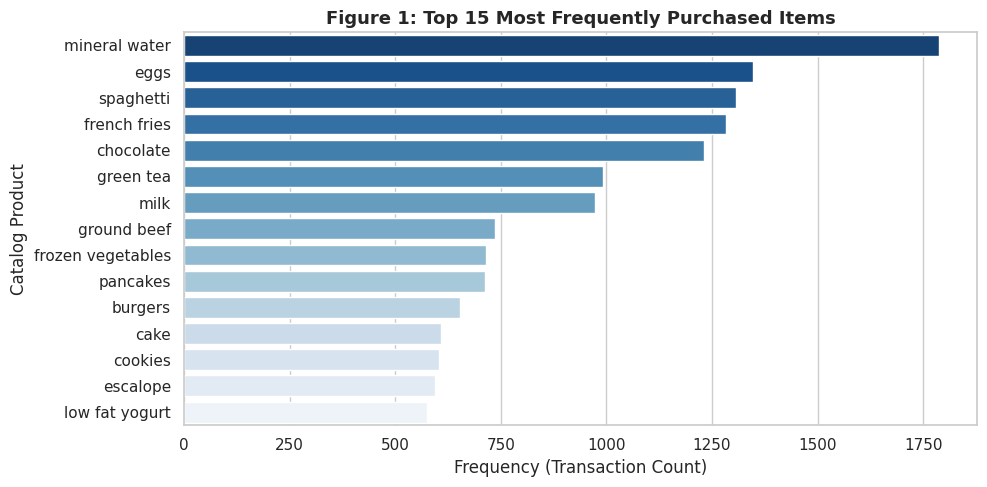

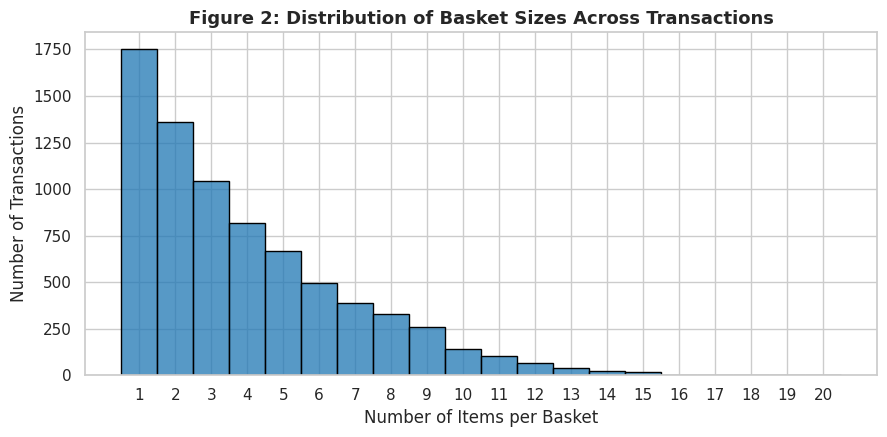

In [ ]:
basket_sizes = [len(tx) for tx in transactions]
all_items = [item for tx in transactions for item in tx]
item_counts = Counter(all_items)
top_15 = item_counts.most_common(15)

print(f'Unique items: {len(item_counts)}')
print(f'Mean basket size: {np.mean(basket_sizes):.2f}')
print(f'Median basket size: {np.median(basket_sizes):.1f}')

plt.figure(figsize=(10, 5))
df_top15 = pd.DataFrame(top_15, columns=['Product', 'Frequency'])
sns.barplot(data=df_top15, x='Frequency', y='Product', palette='Blues_r')
plt.title('Figure 1: Top 15 Most Frequently Purchased Items', fontsize=13, weight='bold')
plt.xlabel('Frequency (Transaction Count)')
plt.ylabel('Catalog Product')
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 4.5))
sns.histplot(basket_sizes, bins=range(1, 22), discrete=True, color='#1f77b4', edgecolor='black')
plt.title('Figure 2: Distribution of Basket Sizes Across Transactions', fontsize=13, weight='bold')
plt.xlabel('Number of Items per Basket')
plt.ylabel('Number of Transactions')
plt.xticks(range(1, 21))
plt.tight_layout()
plt.show()

In [ ]:
mlb = MultiLabelBinarizer()
X = mlb.fit_transform(transactions)
print(f'Binary Matrix Shape: {X.shape}')

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X)
print(f'PC1 Explained Variance: {pca.explained_variance_ratio_[0]*100:.2f}%')
print(f'PC2 Explained Variance: {pca.explained_variance_ratio_[1]*100:.2f}%')

Binary Matrix Shape: (7501, 119)
PC1 Explained Variance: 6.72%
PC2 Explained Variance: 4.47%


In [ ]:
np.random.seed(42)
sample_idx = np.random.choice(len(X), size=2500, replace=False)
X_sample = X[sample_idx]
X_pca_sample = X_pca[sample_idx]

km = KMeans(n_clusters=4, random_state=42, n_init=10).fit(X_sample)
agg = AgglomerativeClustering(n_clusters=4, metric='euclidean', linkage='ward').fit(X_sample)
dbscan = DBSCAN(eps=1.5, min_samples=15).fit(X_sample)
spec = SpectralClustering(n_clusters=4, affinity='nearest_neighbors', n_neighbors=10, random_state=42).fit(X_sample)

def evaluate_algo(data, labels, name):
    mask = labels != -1
    n_c = len(set(labels[mask]))
    if n_c > 1:
        sil = silhouette_score(data[mask], labels[mask])
        db = davies_bouldin_score(data[mask], labels[mask])
    else:
        sil, db = np.nan, np.nan
    return {'Algorithm': name, 'Clusters': n_c, 'Silhouette Score': sil, 'Davies-Bouldin': db}

eval_df = pd.DataFrame([
    evaluate_algo(X_sample, km.labels_, 'K-Means (k=4)'),
    evaluate_algo(X_sample, agg.labels_, 'Hierarchical (k=4)'),
    evaluate_algo(X_sample, dbscan.labels_, 'DBSCAN'),
    evaluate_algo(X_sample, spec.labels_, 'Spectral (k=4)')
])
print(eval_df.to_string(index=False))

         Algorithm  Clusters  Silhouette Score  Davies-Bouldin
     K-Means (k=4)         4          0.067172        3.173375
Hierarchical (k=4)         4          0.051615        3.883082
            DBSCAN         1               NaN             NaN
    Spectral (k=4)         4         -0.048851        2.982721


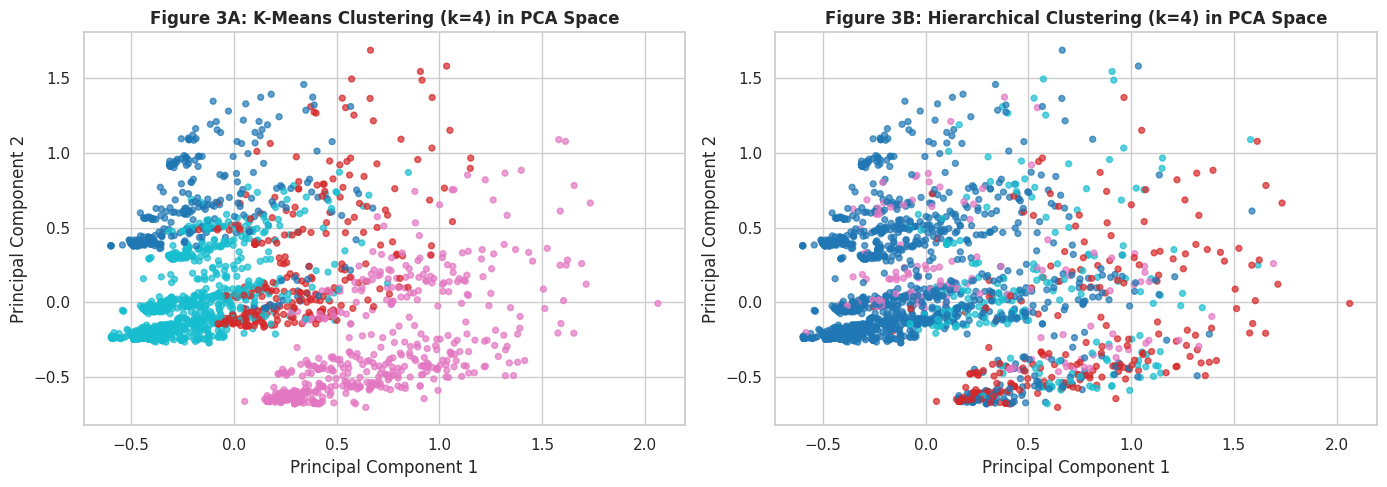

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 3A: K-Means (k=4) in PCA Space
axes[0].scatter(X_pca_sample[:, 0], X_pca_sample[:, 1], c=km.labels_, cmap='tab10', s=18, alpha=0.7)
axes[0].set_title('Figure 3A: K-Means Clustering (k=4) in PCA Space', weight='bold')
axes[0].set_xlabel('Principal Component 1')
axes[0].set_ylabel('Principal Component 2')

# Subplot 3B: Hierarchical Clustering (k=4) in PCA Space
axes[1].scatter(X_pca_sample[:, 0], X_pca_sample[:, 1], c=agg.labels_, cmap='tab10', s=18, alpha=0.7)
axes[1].set_title('Figure 3B: Hierarchical Clustering (k=4) in PCA Space', weight='bold')
axes[1].set_xlabel('Principal Component 1')
axes[1].set_ylabel('Principal Component 2')

plt.tight_layout()
plt.show()